In [ ]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import hw1.solution_utils as su

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110, "display.width", 200)
DATA = os.environ.get("HW1_TRAIN", "./hw1_train.jsonl")
BLUE = "#0072CE"


def counts_table(series, total_label="Всего"):
    """Количество и доля каждого значения + строка с итогом."""
    vc = series.value_counts()
    table = pd.DataFrame({"Количество": vc, "Доля, %": (vc / vc.sum() * 100).round(2)})
    table.loc[total_label] = [vc.sum(), 100.0]
    table["Количество"] = table["Количество"].astype(int)
    return table

In [2]:
dialogs = su.read_dialogs(DATA)
_RE_NON_ALNUM = re.compile(r"[^a-z0-9]+")

rows = []
for d in dialogs:
    us = [t["text"] or "" for t in d["turns"] if t["role"] == "user"]
    asst = [t["text"] or "" for t in d["turns"] if t["role"] == "assistant"]
    labels = d.get("labels") or {}
    rows.append({
        "dialog_id": d["dialog_id"],
        "language": d.get("language"),
        "reaction": labels.get("reaction"),
        "task_type": labels.get("task_type"),
        "n_user": len(us),
        "len_last": len(su.clean_text(us[-1])) if us else 0,
        "len_asst": sum(map(len, asst)) / len(asst) if asst else 0.0,
        "group": (_RE_NON_ALNUM.sub("", us[0].lower())[:80] if us else "") or d["dialog_id"],
    })
eda = pd.DataFrame(rows)
df = eda[eda.reaction.notna()].reset_index(drop=True)   # дальше смотрим только на размеченные диалоги

structure = pd.DataFrame({
    "Показатель": ["Всего диалогов", "Диалогов с известной реакцией", "Диалогов без известной реакции", "Доля размеченных диалогов"],
    "Значение": [f"{len(eda):,}".replace(",", " "), f"{len(df):,}".replace(",", " "),
                 f"{len(eda) - len(df):,}".replace(",", " "), f"{len(df) / len(eda):.0%}"]})
structure

,Показатель,Значение
0,Всего диалогов,10 000
1,Диалогов с известной реакцией,3 000
2,Диалогов без известной реакции,7 000
3,Доля размеченных диалогов,30%


,Количество,"Доля, %"
reaction,,
neutral,1774,59.13
negative,923,30.77
positive,303,10.10
Всего,3000,100.00


neutral чаще positive в 5.9 раза; если всегда отвечать neutral, accuracy = 0.591


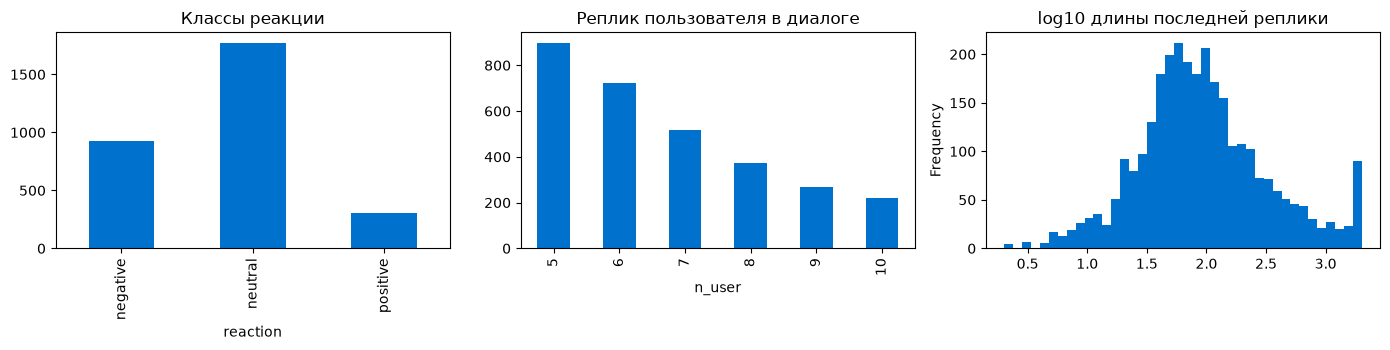

In [3]:
reaction_table = counts_table(df.reaction)
display(reaction_table)

vc = df.reaction.value_counts()
print(f"neutral чаще positive в {vc['neutral'] / vc['positive']:.1f} раза; "
      f"если всегда отвечать neutral, accuracy = {vc['neutral'] / vc.sum():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
df.reaction.value_counts().reindex(su.REACTIONS).plot.bar(ax=axes[0], color=BLUE, title="Классы реакции")
df.n_user.value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE, title="Реплик пользователя в диалоге")
np.log10(df.len_last + 1).plot.hist(bins=40, ax=axes[2], color=BLUE, title="log10 длины последней реплики")
plt.tight_layout(); plt.show()

In [4]:
counts_table(df.language.fillna("нет данных"))

,Количество,"Доля, %"
language,,
en,2978,99.27
ru,22,0.73
Всего,3000,100.00


In [5]:
counts_table(df.task_type.fillna("нет данных"))

,Количество,"Доля, %"
task_type,,
information_seeking,1831,61.03
creation,944,31.47
analysis,137,4.57
open-ended_discovery,88,2.93
Всего,3000,100.00


In [ ]:
s = df.n_user
pd.DataFrame({"Число реплик пользователя": {
    "Минимум": s.min(), "квантиль 1/4": s.quantile(0.25), "Медиана": s.median(),
    "квантиль 3/4": s.quantile(0.75), "Максимум": s.max(),
    "Среднее": round(s.mean(), 3), "Стандартное отклонение": round(s.std(), 3)}})

,Число реплик пользователя
Минимум,5.000
25-й перцентиль,5.000
Медиана,6.000
75-й перцентиль,8.000
Максимум,10.000
Среднее,6.684
Стандартное отклонение,1.576


In [7]:
print("пустых последних реплик:", int((df.len_last == 0).sum()))
n_long = int((df.len_last >= su.MAX_CHARS).sum())
print(f"последних реплик длиной не менее {su.MAX_CHARS} символов: {n_long} ({n_long / len(df):.2%} размеченной выборки)")
display(df.len_last.describe().round(1).to_frame("len_last"))

пустых последних реплик: 0
последних реплик длиной не менее 2000 символов: 74 (2.47% размеченной выборки)


,len_last
count,3000.0
mean,216.8
std,392.8
min,1.0
25%,41.0
50%,81.0
75%,184.0
max,2021.0


In [8]:
# все реплики пользователя по всем диалогам: как часто встречаются служебные сочетания
user_texts = pd.Series([t["text"] or "" for d in dialogs for t in d["turns"] if t["role"] == "user"])
patterns = [("Настоящий символ возврата каретки \\r", "\r"), ("Буквальная последовательность \\\\n", "\\n"),
            ("Буквальная последовательность \\\\r", "\\r"), ("Буквальная последовательность \\\\t", "\\t"),
            ("//", "//"), ("\\\\\\\\", "\\\\")]
pd.DataFrame({"Последовательность": [name for name, _ in patterns],
              "Доля реплик, %": [round(user_texts.str.contains(p, regex=False).mean() * 100, 2) for _, p in patterns]})

,Последовательность,"Доля реплик, %"
0,Настоящий символ возврата каретки \r,0.00
1,Буквальная последовательность \\n,0.40
2,Буквальная последовательность \\r,0.11
3,Буквальная последовательность \\t,0.16
4,//,2.15
5,\\\\,0.05


In [9]:
example = """Привет! Смотри https://example.com/page?id=42&x=1 и www.test.org — там всё есть.
Вот формула: \\theta + \\nu = \\rho, и ещё \\frac{1}{2} \\cdot \\sqrt{x}.
Код:
```python
def foo(x):
    return x ** 2 + 1
Текст текст текст текст текст текст текст текст текст текст текст текст текст
текст текст текст текст текст текст текст текст текст текст текст текст текст
текст текст текст текст текст текст текст текст текст текст текст текст текст."""
print(su.clean_text(example))

Привет! Смотри и — там всё есть. Код: zzcode zzmath zzurl


In [10]:
display(df.groupby("reaction")[["n_user", "len_last", "len_asst"]].median().reindex(su.REACTIONS).round(2))
su.show_table(pd.crosstab(df.n_user, df.reaction, normalize="index").round(3))

,n_user,len_last,len_asst
reaction,,,
negative,6.0,78.0,1350.33
neutral,6.0,85.0,1370.19
positive,7.0,63.0,1098.62


reaction,negative,neutral,positive
n_user,,,
5,0.280,0.625,0.095
6,0.320,0.598,0.082
7,0.312,0.572,0.116
8,0.344,0.554,0.102
9,0.309,0.561,0.130
10,0.305,0.577,0.118


In [11]:
grp = df.groupby("group").agg(n=("reaction", "size"), n_labels=("reaction", "nunique"))
dup = grp[grp.n > 1]
print("групп, в которых больше одного диалога:", len(dup))
print("диалогов в этих группах:", int(dup.n.sum()))
print("групп с разными метками реакции:", int((dup.n_labels > 1).sum()))

групп, в которых больше одного диалога: 16
диалогов в этих группах: 34
групп с разными метками реакции: 5


In [12]:
# примеры групп с противоречивыми метками
for g in dup[dup.n_labels > 1].sort_values("n", ascending=False).head(3).index:
    print(f"\nгруппа {g[:60]!r}")
    print(eda[(eda.group == g) & eda.reaction.notna()][["dialog_id", "reaction", "n_user", "len_last"]].to_string(index=False))


группа 'hi'
  dialog_id reaction  n_user  len_last
d47401af151  neutral       7       232
d04c4043110 negative       6        78
d309087d4fe positive       8        10

группа 'hello'
  dialog_id reaction  n_user  len_last
d4ed4706195  neutral       5        25
d41fcb565b0 negative      10       155

группа 'hiiamwritingabookandwanttoexploresomeaspectsofpersonalityiam'
  dialog_id reaction  n_user  len_last
dfd03a6b0a7  neutral       6       125
d20a9a0968f positive      10        93


In [13]:
vc = df.reaction.value_counts()
print(f"Диалогов: {len(eda)}, с реакцией: {len(df)} ({len(df) / len(eda):.0%})")
print("Классы:", {k: f"{v} ({v / len(df):.2%})" for k, v in vc.items()})
print("Языки:", df.language.value_counts().to_dict())
print("Типы задач:", df.task_type.value_counts().to_dict())
print(f"Реплик пользователя: медиана {df.n_user.median():g}, среднее {df.n_user.mean():.3f}")
print(f"Длинных последних реплик (>= {su.MAX_CHARS}): {n_long}")
print(f"Групп-повторов: {len(dup)}, диалогов в них: {int(dup.n.sum())}, с разными метками: {int((dup.n_labels > 1).sum())}")

Диалогов: 10000, с реакцией: 3000 (30%)
Классы: {'neutral': '1774 (59.13%)', 'negative': '923 (30.77%)', 'positive': '303 (10.10%)'}
Языки: {'en': 2978, 'ru': 22}
Типы задач: {'information_seeking': 1831, 'creation': 944, 'analysis': 137, 'open-ended_discovery': 88}
Реплик пользователя: медиана 6, среднее 6.684
Длинных последних реплик (>= 2000): 74
Групп-повторов: 16, диалогов в них: 34, с разными метками: 5
